In [1]:
import requests
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
url = "https://stablecoins.llama.fi/stablecoins?includePrices=true"
response = requests.get(url)
data = response.json()

print(response.status_code)
print(data.keys())

200
dict_keys(['peggedAssets', 'chains'])


In [3]:
assets = data["peggedAssets"]
print("Number of stablecoins:", len(assets))

for coin in assets:
    if coin["symbol"] in ["USDT", "USDC"]:
        print(coin["id"], coin["symbol"], coin["name"])

Number of stablecoins: 435
1 USDT Tether
2 USDC USD Coin


# FOR USDT


In [4]:


usdt = [c for c in assets if c["symbol"] == "USDT"][0]
usdc = [c for c in assets if c["symbol"] == "USDC"][0]

print("USDT is on", len(usdt["chainCirculating"]), "chains")
print("USDC is on", len(usdc["chainCirculating"]), "chains")

print(usdt["chainCirculating"]["Tron"])

USDT is on 131 chains
USDC is on 161 chains
{'current': {'peggedUSD': 92178511822.9258}, 'circulatingPrevDay': {'peggedUSD': 92390782294.4014}, 'circulatingPrevWeek': {'peggedUSD': 92312249153.4518}, 'circulatingPrevMonth': {'peggedUSD': 92572368978.81776}}


The first two lines pick out the full USDT and USDC records and save them as usdt and usdc. The [0] takes the first match. There’s only one each, but the filter returns a list.

chainCirculating is the part of each record that holds the amount of the coin on each blockchain. len(...) counts how many chains it’s on.

The last line prints USDT’s entry for Tron, so we can see the exact format of one chain’s data.

In [5]:
rows = []

for chain, values in usdt["chainCirculating"].items():
    rows.append({"chain": chain, "USDT": values["current"].get("peggedUSD", 0)})

df_usdt = pd.DataFrame(rows)
print(df_usdt.sort_values("USDT", ascending=False).head(10))

         chain          USDT
6         Tron  9.217851e+10
36    Ethereum  6.757805e+10
63         BSC  9.172088e+09
124     Solana  2.441520e+09
82      Plasma  8.854316e+08
73    Arbitrum  8.100200e+08
23     Polygon  7.767009e+08
86         TON  5.001118e+08
115     Mantle  4.356836e+08
71   Avalanche  3.856596e+08


FOR USDC

In [6]:
rows = []

for chain, values in usdc["chainCirculating"].items():
    rows.append({"chain": chain, "USDC": values["current"].get("peggedUSD", 0)})

df_usdc = pd.DataFrame(rows)
print(df_usdc.sort_values("USDC", ascending=False).head(10))

              chain          USDC
47         Ethereum  4.287780e+10
154          Solana  7.025481e+09
137  Hyperliquid L1  6.577646e+09
65             Base  4.208203e+09
92         Arbitrum  2.278572e+09
30          Polygon  1.679129e+09
82              BSC  1.588777e+09
108             Arc  1.286568e+09
99              Sui  3.630509e+08
115         Stellar  3.428712e+08


In [7]:
df = pd.merge(df_usdt, df_usdc, on="chain", how="outer")
df = df.fillna(0)

print(df.shape)
print(df.head())

(177, 3)
      chain          USDT          USDC
0        0G  9.986500e-01  1.733304e+02
1      ALEO  0.000000e+00  4.513386e+06
2  Abstract  3.363240e+05  2.037442e+06
3  Algorand  8.402145e+05  1.153410e+08
4    Anubis  1.387259e+06  2.063365e-01


177 chains in total. USDT is on 131 and USDC on 161, so about 115 chains carry both. The arithmetic: 131 + 161 − 177 = 115.

The rows are sorted alphabetically, so these first five are tiny chains (0G has less than $1 of USDT).
ALEO shows USDT = 0, which proves fillna(0) worked: USDC is there, USDT isn’t.

In [8]:
df["USDT_%"] = df["USDT"] / df["USDT"].sum() * 100
df["USDC_%"] = df["USDC"] / df["USDC"].sum() * 100

print("Total USDT: $", round(df["USDT"].sum() / 1e9, 1), "B")
print("Total USDC: $", round(df["USDC"].sum() / 1e9, 1), "B")

Total USDT: $ 176.8 B
Total USDC: $ 70.6 B


df["USDT"].sum() adds up USDT across all 177 chains to get the total supply.
Dividing each chain’s amount by the total and multiplying by 100 gives that chain’s percentage share. The result is saved in a new column, USDT_%.

The same is done for USDC.
The two print lines show total supply in billions (/ 1e9 divides by 1,000,000,000), rounded to 1 decimal place, which is easier to read than 9.2e+10.

#Why this approach:

Raw dollar amounts are hard to compare because USDT is much bigger than USDC overall. Percentages make them comparable. For example, “Tron holds X% of all USDT” vs “Ethereum holds Y% of all USDC.”

Percentages also measure concentration: whether a coin depends on one chain or is spread out. That’s a key point in your story.

Seeing the totals also checks the data against public figures. USDT should be roughly in the $180B+ range and USDC somewhat lower.

In [9]:
print(df.sort_values("USDT_%", ascending=False)[["chain", "USDT_%"]].head(5).round(1))
print()
print(df.sort_values("USDC_%", ascending=False)[["chain", "USDC_%"]].head(5).round(1))

        chain  USDT_%
156      Tron    52.1
45   Ethereum    38.2
16        BSC     5.2
135    Solana     1.4
117    Plasma     0.5

              chain  USDC_%
45         Ethereum    60.8
135          Solana    10.0
66   Hyperliquid L1     9.3
18             Base     6.0
8          Arbitrum     3.2


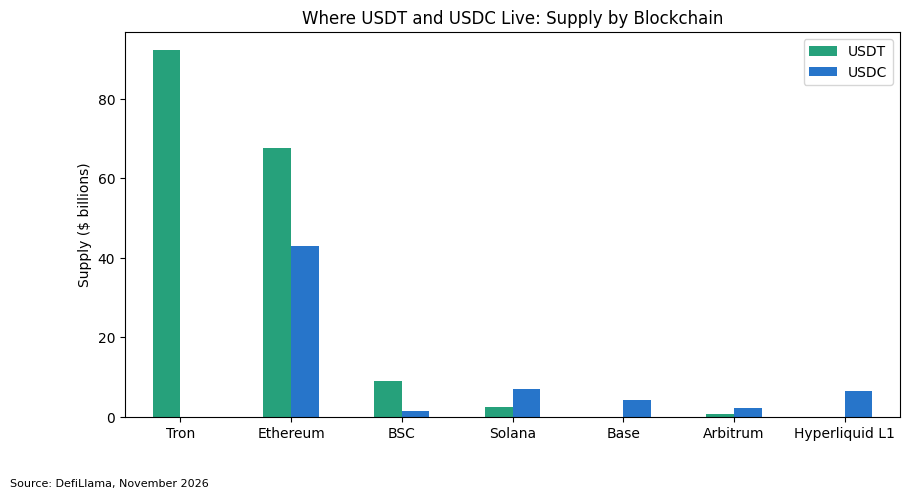

In [10]:
# USDT vs USDC supply by chain
chains = ["Tron", "Ethereum", "BSC", "Solana", "Base", "Arbitrum", "Hyperliquid L1"]
top = df[df["chain"].isin(chains)].set_index("chain").loc[chains]

top[["USDT", "USDC"]].div(1e9).plot(kind="bar", color=["#26A17B", "#2775CA"], figsize=(10, 5))

plt.title("Where USDT and USDC Live: Supply by Blockchain")
plt.ylabel("Supply ($ billions)")
plt.xlabel("")
plt.xticks(rotation=0)
plt.figtext(0.01, -0.03, "Source: DefiLlama, November 2026", fontsize=8)
plt.savefig("chart1_supply_by_chain.png", dpi=200, bbox_inches="tight")
plt.show()

# How concentrated is each coin?

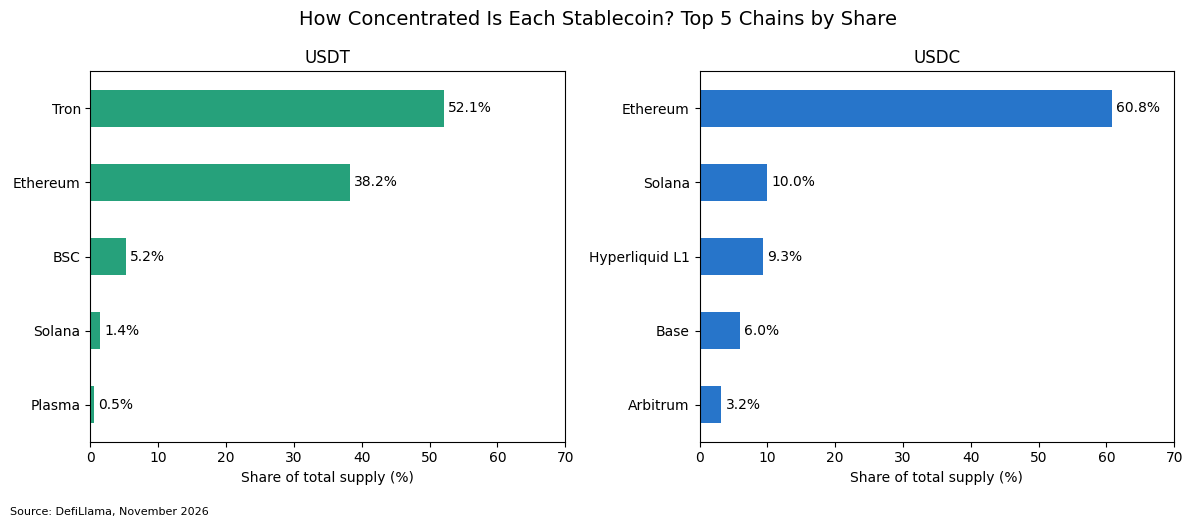

In [12]:
usdt_top = df.sort_values("USDT_%", ascending=False).head(5).set_index("chain")["USDT_%"]
usdc_top = df.sort_values("USDC_%", ascending=False).head(5).set_index("chain")["USDC_%"]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

usdt_top[::-1].plot(kind="barh", ax=axes[0], color="#26A17B")
usdc_top[::-1].plot(kind="barh", ax=axes[1], color="#2775CA")

axes[0].set_title("USDT")
axes[1].set_title("USDC")

for ax in axes:
    ax.set_xlim(0, 70)
    ax.set_ylabel("")
    ax.set_xlabel("Share of total supply (%)")
    ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)

fig.suptitle("How Concentrated Is Each Stablecoin? Top 5 Chains by Share", fontsize=14)
fig.text(0.01, -0.03, "Source: DefiLlama, November 2026", fontsize=8)
plt.tight_layout()
plt.savefig("chart2_share_by_chain.png", dpi=200, bbox_inches="tight")
plt.show()

# Download USDT’s supply history

In [13]:
url = "https://stablecoins.llama.fi/stablecoincharts/all?stablecoin=1"
usdt_hist = requests.get(url).json()

print(len(usdt_hist))
print(usdt_hist[0])
print(usdt_hist[-1])

3266
{'date': '1511913600', 'totalCirculating': {'peggedUSD': 109970}, 'totalCirculatingUSD': {'peggedUSD': 110105}}
{'date': '1794009600', 'totalCirculating': {'peggedUSD': 176997377298.13}, 'totalUnreleased': {'peggedUSD': 10888895965.77}, 'totalCirculatingUSD': {'peggedUSD': 176776130576.51}, 'totalMintedUSD': {'peggedUSD': 0}, 'totalBridgedToUSD': {'peggedUSD': 0}}


In [15]:
# convert them into normal dates:
start = pd.to_datetime(int(usdt_hist[0]["date"]), unit="s")
end = pd.to_datetime(int(usdt_hist[-1]["date"]), unit="s")

print("From:", start.date())
print("To:  ", end.date())
print("Days:", len(usdt_hist))

From: 2017-11-29
To:   2026-11-07
Days: 3266


In [16]:
usdt_df = pd.DataFrame(usdt_hist)

usdt_df["date"] = pd.to_datetime(usdt_df["date"].astype(int), unit="s")
usdt_df["USDT"] = usdt_df["totalCirculatingUSD"].apply(lambda x: x.get("peggedUSD", 0))

usdt_df = usdt_df[["date", "USDT"]]
usdt_df = usdt_df[usdt_df["date"] >= "2021-01-01"]

print(usdt_df.head(3))
print(usdt_df.tail(3))

           date          USDT
1129 2021-01-01  2.003856e+10
1130 2021-01-02  2.057844e+10
1131 2021-01-03  2.140410e+10
           date          USDT
3263 2026-11-05  1.776423e+11
3264 2026-11-06  1.774853e+11
3265 2026-11-07  1.767761e+11


# Download USDT’s supply history

In [17]:
url = "https://stablecoins.llama.fi/stablecoincharts/all?stablecoin=2"
usdc_hist = requests.get(url).json()

usdc_df = pd.DataFrame(usdc_hist)
usdc_df["date"] = pd.to_datetime(usdc_df["date"].astype(int), unit="s")
usdc_df["USDC"] = usdc_df["totalCirculatingUSD"].apply(lambda x: x.get("peggedUSD", 0))

usdc_df = usdc_df[["date", "USDC"]]
usdc_df = usdc_df[usdc_df["date"] >= "2021-01-01"]

print(usdc_df.head(3))
print(usdc_df.tail(3))

          date          USDC
843 2021-01-01  3.918737e+09
844 2021-01-02  4.105938e+09
845 2021-01-03  4.187979e+09
           date          USDC
2977 2026-11-05  7.112710e+10
2978 2026-11-06  7.071648e+10
2979 2026-11-07  7.058467e+10


January 2021: about $20.0B → November 2026: about 176.8B Dollars. USDT grew roughly 8.8 times in under 6 years.

The latest value (176.78B)Dollars matches Step 8’s total ($176.8B), so the two DefiLlama sources agree.
The last date shows 7 November because DefiLlama uses UTC time, which is already the next day there. That’s normal.
The row numbers (index 1129 to 3265) show the full history goes back about 3,266 days, to around late 2017, as expected

USDC’s numbers also line up:

January 2021: about 3.9B Dollars → November 2026: about $70.6B, matching Step 8 again.
USDC grew about 18 times, faster than USDT’s 8.8 times in percentage terms, because it started from a much smaller base. That’s a nice nuance for your article: USDT is bigger, but USDC has grown faster since 2021.

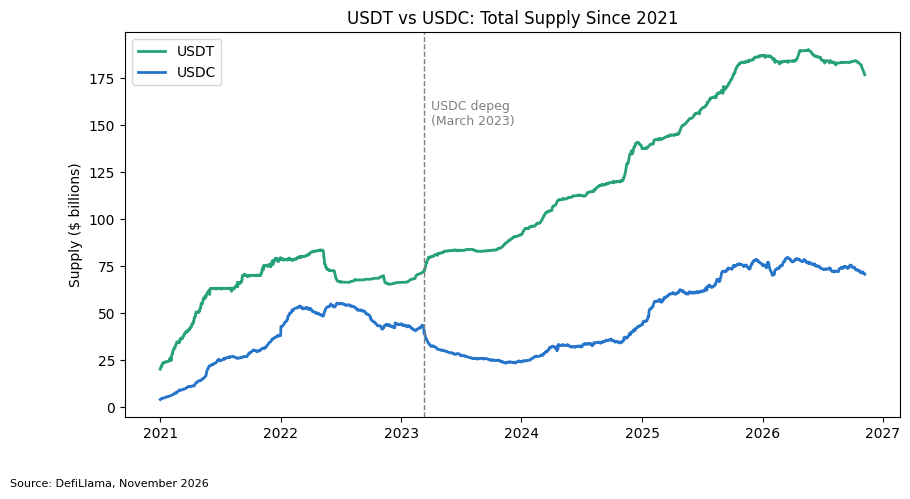

In [18]:
hist = pd.merge(usdt_df, usdc_df, on="date", how="inner")

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(hist["date"], hist["USDT"] / 1e9, color="#26A17B", linewidth=2, label="USDT")
ax.plot(hist["date"], hist["USDC"] / 1e9, color="#2775CA", linewidth=2, label="USDC")

ax.axvline(pd.Timestamp("2023-03-11"), color="grey", linestyle="--", linewidth=1)
ax.text(pd.Timestamp("2023-04-01"), 150, "USDC depeg\n(March 2023)", fontsize=9, color="grey")

ax.set_title("USDT vs USDC: Total Supply Since 2021")
ax.set_ylabel("Supply ($ billions)")
ax.legend()

fig.text(0.01, -0.03, "Source: DefiLlama, November 2026", fontsize=8)
plt.savefig("chart3_supply_over_time.png", dpi=200, bbox_inches="tight")
plt.show()

In [19]:
# Download the peg (price) data
url = "https://stablecoins.llama.fi/stablecoinprices"
prices = requests.get(url).json()

print(len(prices))
print(prices[-1]["date"])
print(prices[-1]["prices"].get("tether"))
print(prices[-1]["prices"].get("usd-coin"))

2134
1794009600
0.99875
0.9998385301749999


In [20]:
peg = pd.DataFrame(prices)
peg["date"] = pd.to_datetime(peg["date"].astype(int), unit="s")
peg["USDT"] = peg["prices"].apply(lambda x: x.get("tether"))
peg["USDC"] = peg["prices"].apply(lambda x: x.get("usd-coin"))

peg = peg[["date", "USDT", "USDC"]].dropna()
peg = peg[peg["date"] >= "2021-01-01"]

for coin in ["USDT", "USDC"]:
    dev = (peg[coin] - 1).abs() * 100
    print(f"{coin}: average gap {dev.mean():.3f}%  |  biggest gap {dev.max():.2f}%  on {peg.loc[dev.idxmax(), 'date'].date()}")

USDT: average gap 0.088%  |  biggest gap 1.14%  on 2021-03-01
USDC: average gap 0.077%  |  biggest gap 3.89%  on 2023-03-12


Day to day, both are very stable, and USDC is slightly steadier. On $1,000, a 0.08% gap is only about 80 cents.

In a crisis, USDC had the bigger shock. The day after Silicon Valley Bank collapsed, USDC was almost 4% off its peg, so someone receiving $10,000 would have effectively lost about 390 dollars that day.

The data is daily, which smooths out short drops. During the SVB weekend, USDC briefly traded as low as about $0.87.

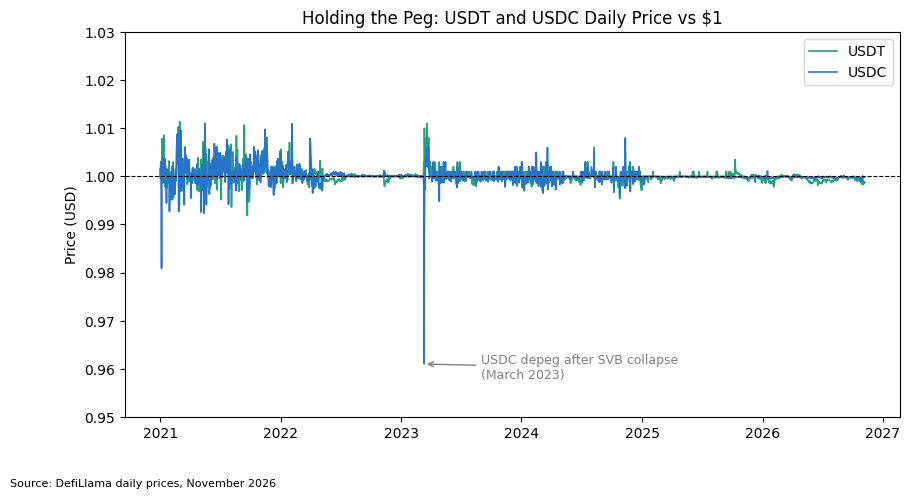

In [21]:
# peg stability

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(peg["date"], peg["USDT"], color="#26A17B", linewidth=1.2, label="USDT")
ax.plot(peg["date"], peg["USDC"], color="#2775CA", linewidth=1.2, label="USDC")

ax.axhline(1.0, color="black", linestyle="--", linewidth=0.8)
ax.set_ylim(0.95, 1.03)

ax.annotate("USDC depeg after SVB collapse\n(March 2023)",
            xy=(pd.Timestamp("2023-03-12"), 0.961),
            xytext=(pd.Timestamp("2023-09-01"), 0.958),
            arrowprops=dict(arrowstyle="->", color="grey"),
            fontsize=9, color="grey")

ax.set_title("Holding the Peg: USDT and USDC Daily Price vs $1")
ax.set_ylabel("Price (USD)")
ax.legend()

fig.text(0.01, -0.03, "Source: DefiLlama daily prices, November 2026", fontsize=8)
plt.savefig("chart4_peg_stability.png", dpi=200, bbox_inches="tight")
plt.show()

In [22]:
ramp_pct = 1.0   # assumed on/off-ramp cost in % (buying + selling). Adjust from your experience.

cost = pd.DataFrame({
    "route":    ["Traditional: avg to Africa", "Traditional: US → Nigeria",
                 "USDT on Tron", "Stablecoin on Ethereum", "Stablecoin on Solana"],
    "fee_usd":  [None, None, 2.00, 0.22, 0.001],
    "cost_pct": [8.2, 3.8, None, None, None]
})

cost.loc[2:, "cost_pct"] = cost.loc[2:, "fee_usd"] / 200 * 100 + ramp_pct
cost["cost_on_$200"] = cost["cost_pct"] / 100 * 200

print(cost.round(2))

                        route  fee_usd  cost_pct  cost_on_$200
0  Traditional: avg to Africa      NaN      8.20         16.40
1   Traditional: US → Nigeria      NaN      3.80          7.60
2                USDT on Tron     2.00      2.00          4.00
3      Stablecoin on Ethereum     0.22      1.11          2.22
4        Stablecoin on Solana     0.00      1.00          2.00


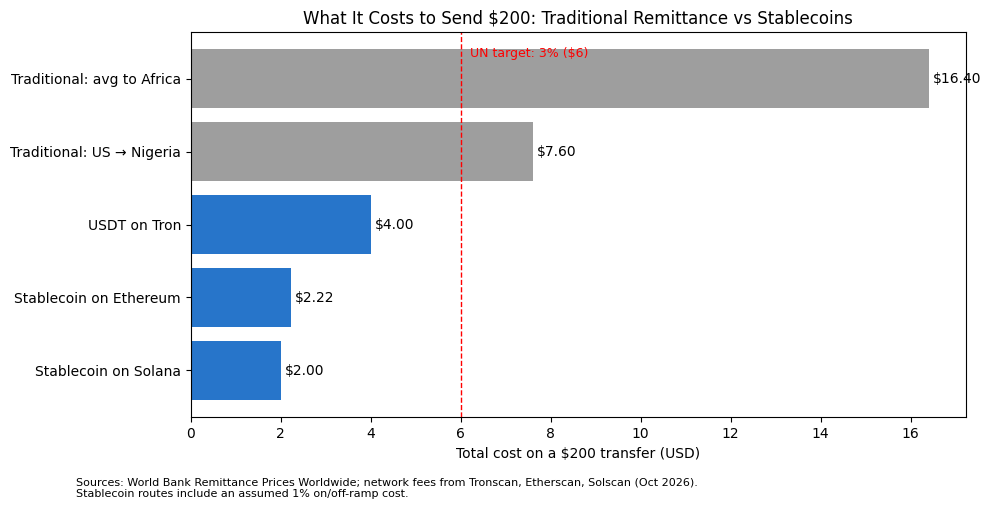

In [23]:
plot_df = cost.sort_values("cost_on_$200")
colors = ["#2775CA" if "Stablecoin" in r or "USDT" in r else "#9E9E9E" for r in plot_df["route"]]

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(plot_df["route"], plot_df["cost_on_$200"], color=colors)

ax.bar_label(bars, labels=[f"${v:.2f}" for v in plot_df["cost_on_$200"]], padding=3)
ax.axvline(6, color="red", linestyle="--", linewidth=1)
ax.text(6.2, 4.3, "UN target: 3% ($6)", color="red", fontsize=9)

ax.set_title("What It Costs to Send $200: Traditional Remittance vs Stablecoins")
ax.set_xlabel("Total cost on a $200 transfer (USD)")

fig.text(0.01, -0.05,
         "Sources: World Bank Remittance Prices Worldwide; network fees from Tronscan, Etherscan, Solscan (Oct 2026).\n"
         "Stablecoin routes include an assumed 1% on/off-ramp cost.", fontsize=8)
plt.savefig("chart5_cost_of_200.png", dpi=200, bbox_inches="tight")
plt.show()

In [24]:
scorecard = pd.DataFrame(index=["USDT", "USDC"])

for coin in ["USDT", "USDC"]:
    top_row = df.sort_values(coin, ascending=False).iloc[0]
    dev = (peg[coin] - 1).abs() * 100

    scorecard.loc[coin, "Total supply ($B)"] = round(df[coin].sum() / 1e9, 1)
    scorecard.loc[coin, "Main chain"] = top_row["chain"]
    scorecard.loc[coin, "Main chain share (%)"] = round(top_row[f"{coin}_%"], 1)
    scorecard.loc[coin, "Growth since Jan 2021 (x)"] = round(hist[coin].iloc[-1] / hist[coin].iloc[0], 1)
    scorecard.loc[coin, "Avg peg gap (%)"] = round(dev.mean(), 3)
    scorecard.loc[coin, "Worst peg gap (%)"] = round(dev.max(), 2)

print(scorecard.T)

                            USDT      USDC
Total supply ($B)          176.8      70.6
Main chain                  Tron  Ethereum
Main chain share (%)        52.1      60.8
Growth since Jan 2021 (x)    8.8      18.0
Avg peg gap (%)            0.088     0.077
Worst peg gap (%)           1.14      3.89
